# E3 · LoRA on LLM attention + all 32 ViT blocks (2,000 training images)

| Setting | Value |
|---|---|
| Base model | Qwen2.5-VL-3B-Instruct, fp16, SDPA attention |
| LoRA | r = 16, α = 32, dropout 0.05 on LLM `q/k/v/o_proj` + ViT `attn.qkv` / `attn.proj` of all 32 blocks (11.3 M trainable params, 0.30%) |
| Learning rate | 1e-5 for ViT LoRA, 5e-5 for LLM LoRA (differential), constant |
| Data | 2,000 random train captions, 200 random val images (seed 2026) |
| Image budget | 224² – 448² pixels → 256 visual tokens per 512×512 image |
| Hardware | 1× T4 (16 GB) |

Result: best of E0–E5 (BERT-BLEU₄ 0.6659 on the 200 val images, see `compare_experiments.ipynb`).

Known issue, kept as recorded: the save cell zips predictions with `val_records` instead of `val_subset`, so the `image_id` field
of the saved predictions is wrong (reference/prediction pairs are correct). `results/experiments/E3/predictions.json` has the
corrected ids. The notebook body below starts from the shared experiment template, so its introduction still says "baseline".

# VRSBench Image Captioning — Baseline
## Qwen2.5-VL-3B-Instruct | Task 01

This notebook establishes a **reproducible zero-shot baseline** for the VRSBench image-captioning task.

### Problem statement
The task is to generate natural-language captions for remote-sensing images from the open-source **VRSBench** dataset and study how training/inference optimizations affect model quality, convergence, speed, and resource usage.

### What this notebook measures
- Pretrained **Qwen2.5-VL-3B-Instruct** with **no fine-tuning**.
- Caption quality using **corpus BLEU-4** and **BERTScore**.
- Generation speed in seconds/image.
- Peak GPU memory used during generation.
- Qualitative examples of predictions vs. reference captions.
- Checkpointed predictions so the run can resume after interruption.

### Why this baseline matters
Every optimization in the next stage should be reported as a delta against this measured reference point. The intended comparison dimensions are:

`Δ BLEU-4 | Δ BERTScore-F1 | Δ seconds/image | Δ peak GPU memory`

> **Important:** this notebook is the baseline. It does not claim that the model is already optimized; it creates the control experiment against which later LoRA/QLoRA, decoding, mixed-precision, batching, image-resolution, and other optimizations can be compared.

## 1. Experimental design

| Component | Baseline choice |
|---|---|
| Dataset | `xiang709/VRSBench` from Hugging Face Hub |
| Evaluation data | `VRSBench_EVAL_Cap.json` + corresponding validation images |
| Model | `Qwen/Qwen2.5-VL-3B-Instruct` |
| Adaptation | None (zero-shot) |
| Prompt | One detailed sentence describing the remote-sensing image |
| Decoding | Greedy (`do_sample=False`, `num_beams=1`) |
| Evaluation | BLEU-4 + BERTScore (P/R/F1) |
| Checkpointing | Append predictions after every batch |
| Hardware target | Kaggle T4 / T4×2; code auto-detects CUDA |

VRSBench's Hugging Face repository currently contains the caption evaluation JSON and validation-image archive. The Qwen2.5-VL model card documents direct Transformers inference with `AutoProcessor` and `Qwen2_5_VLForConditionalGeneration`.

In [ ]:
!pip install -q -U \
    transformers \
    accelerate \
    peft \
    datasets \
    huggingface_hub \
    qwen-vl-utils \
    nltk \
    rouge-score

In [1]:
import os
import json
import time
import random
import math
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

from PIL import Image

from huggingface_hub import hf_hub_download

from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration,
)

from peft import (
    LoraConfig,
    get_peft_model,
)

from qwen_vl_utils import process_vision_info

# Metrics
import nltk
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer

nltk.download("wordnet")
nltk.download("omw-1.4")


# =========================================================
# Reproducibility
# =========================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# =========================================================
# Device
# =========================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )


# =========================================================
# Model
# =========================================================

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"


# =========================================================
# VRSBench
# =========================================================

HF_DATASET_ID = "xiang709/VRSBench"

DATA_ROOT = Path("/kaggle/working/VRSBench")

TRAIN_IMAGE_DIR = DATA_ROOT / "Images_train"
VAL_IMAGE_DIR   = DATA_ROOT / "Images_val"

HF_CACHE_DIR = DATA_ROOT / "hf_files"

HF_CACHE_DIR.mkdir(parents=True, exist_ok=True)


# =========================================================
# Experiment config
# =========================================================

TRAIN_SAMPLES = 2000
VAL_SAMPLES = 200

EPOCHS = 1

BATCH_SIZE = 1

LEARNING_RATE = 5e-5

WEIGHT_DECAY = 0.01

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05

MAX_NEW_TOKENS = 160

# E0 fixed resolution budget.
# This preserves aspect ratio while limiting visual input size.
MIN_PIXELS = 224 * 224
MAX_PIXELS = 448 * 448
# MAX_PIXELS = 560 * 560 # for E2

PROMPT = "Describe the image in detail."

print("Configuration loaded.")

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB
Configuration loaded.


[nltk_data] Error loading wordnet: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading omw-1.4: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

In [2]:
TRAIN_JSON = hf_hub_download(
    repo_id=HF_DATASET_ID,
    filename="VRSBench_train.json",
    repo_type="dataset",
    local_dir=str(HF_CACHE_DIR),
)

VAL_JSON = hf_hub_download(
    repo_id=HF_DATASET_ID,
    filename="VRSBench_EVAL_Cap.json",
    repo_type="dataset",
    local_dir=str(HF_CACHE_DIR),
)

print("Train annotation:", TRAIN_JSON)
print("Val annotation:", VAL_JSON)

Train annotation: /kaggle/working/VRSBench/hf_files/VRSBench_train.json
Val annotation: /kaggle/working/VRSBench/hf_files/VRSBench_EVAL_Cap.json


In [3]:
print("Train dir exists:", TRAIN_IMAGE_DIR.exists())
print("Val dir exists:", VAL_IMAGE_DIR.exists())

if TRAIN_IMAGE_DIR.exists():
    print("Train images:", len(list(TRAIN_IMAGE_DIR.rglob("*"))))

if VAL_IMAGE_DIR.exists():
    print("Val images:", len(list(VAL_IMAGE_DIR.rglob("*"))))

Train dir exists: True
Val dir exists: True
Train images: 20265
Val images: 9351


In [4]:
from zipfile import ZipFile

if not TRAIN_IMAGE_DIR.exists():
    print("Downloading train images...")

    train_zip = hf_hub_download(
        repo_id=HF_DATASET_ID,
        filename="Images_train.zip",
        repo_type="dataset",
        local_dir=str(HF_CACHE_DIR),
    )

    TRAIN_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

    with ZipFile(train_zip, "r") as z:
        z.extractall(TRAIN_IMAGE_DIR)

    print("Train extraction complete.")

for p in Path("/kaggle/working/VRSBench").rglob("Images_train.zip"):
    print("Deleting:", p)
    p.unlink()

if not VAL_IMAGE_DIR.exists():
    print("Downloading validation images...")

    val_zip = hf_hub_download(
        repo_id=HF_DATASET_ID,
        filename="Images_val.zip",
        repo_type="dataset",
        local_dir=str(HF_CACHE_DIR),
    )

    VAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

    with ZipFile(val_zip, "r") as z:
        z.extractall(VAL_IMAGE_DIR)

    print("Validation extraction complete.")
    
for p in Path("/kaggle/working/VRSBench").rglob("Images_val.zip"):
    print("Deleting:", p)
    p.unlink()

In [5]:
def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


train_raw = load_json(TRAIN_JSON)
val_raw = load_json(VAL_JSON)

print("Train records:", len(train_raw))
print("Val records:", len(val_raw))

print("\nTrain sample:")
print(json.dumps(train_raw[0], indent=2, ensure_ascii=False)[:3000])

print("\nVal sample:")
print(json.dumps(val_raw[0], indent=2, ensure_ascii=False)[:3000])

Train records: 142390
Val records: 9350

Train sample:
{
  "id": "Final_Data/v1.2",
  "image": "00002_0000.png",
  "conversations": [
    {
      "from": "human",
      "value": "<image>\n[caption] Could you describe the contents of this image for me?"
    },
    {
      "from": "gpt",
      "value": "The image, sourced from GoogleEarth, shows a rural area with an expressway-toll-station situated at the center. Alongside the toll station, multiple small vehicles are visible, with one positioned on the middle-left and another that is the right-most in the center relative to the toll station."
    }
  ]
}

Val sample:
{
  "image_id": "P0003_0002.png",
  "ground_truth": "The aerial image from GoogleEarth features a group of large yellow buses lined up on the left side, and two small vehicles, one on the top-right and another large vehicle on the bottom-right side of the image. The buses are parked in a lot adjacent to a green area and a road running roughly north-south.",
  "question": "D

In [6]:
def extract_caption_from_conversations(conversations):
    """
    Find the final assistant/gpt response.
    """
    for turn in reversed(conversations):
        role = turn.get("from") or turn.get("role")

        if role in {"gpt", "assistant"}:
            value = turn.get("value") or turn.get("content")
            if isinstance(value, str):
                return value.strip()

    return None

In [7]:
def extract_image_id(record):
    """
    Handle common VRSBench/LLaVA-style keys.
    """
    candidates = [
        record.get("image"),
        record.get("image_id"),
        record.get("id"),
    ]

    for value in candidates:
        if value is None:
            continue

        if isinstance(value, list):
            if len(value) > 0:
                value = value[0]

        if isinstance(value, str):
            return Path(value).name

    return None

In [8]:
from collections import Counter

def get_human_text(record):
    conversations = record.get("conversations", [])

    for turn in conversations:
        if turn.get("from") == "human":
            return turn.get("value", "")

    return ""


counter = Counter()

for record in train_raw:
    human_text = get_human_text(record)

    if "[caption]" in human_text.lower():
        counter["caption"] += 1
    else:
        counter["other"] += 1

print(counter)

Counter({'other': 122126, 'caption': 20264})


In [9]:
def extract_train_caption_record(record):
    """
    Extract one caption-training example from VRSBench train JSON.
    """

    image_id = record.get("image")

    conversations = record.get("conversations", [])

    human_text = None
    caption = None

    for turn in conversations:

        role = turn.get("from")
        value = turn.get("value", "")

        if role == "human":
            human_text = value

        elif role == "gpt":
            caption = value

    # Safety check
    if image_id is None:
        return None

    if caption is None:
        return None

    # Keep only caption examples
    if human_text is None:
        return None

    if "[caption]" not in human_text.lower():
        return None

    return {
        "image_id": Path(image_id).name,
        "caption": caption.strip(),
        "task": "caption",
    }

In [10]:
train_records_all = []

for record in train_raw:

    parsed = extract_train_caption_record(record)

    if parsed is not None:
        train_records_all.append(parsed)


print("Caption training records:", len(train_records_all))
print(train_records_all[0])

Caption training records: 20264
{'image_id': '00002_0000.png', 'caption': 'The image, sourced from GoogleEarth, shows a rural area with an expressway-toll-station situated at the center. Alongside the toll station, multiple small vehicles are visible, with one positioned on the middle-left and another that is the right-most in the center relative to the toll station.', 'task': 'caption'}


In [11]:
def extract_val_caption_record(record):

    image_id = record.get("image_id")
    caption = record.get("ground_truth")

    if image_id is None:
        return None

    if caption is None:
        return None

    return {
        "image_id": Path(image_id).name,
        "caption": caption.strip(),
        "task": "caption",
    }

In [12]:
val_records_all = []

for record in val_raw:

    parsed = extract_val_caption_record(record)

    if parsed is not None:
        val_records_all.append(parsed)


print("Validation caption records:", len(val_records_all))
print(val_records_all[0])

Validation caption records: 9350
{'image_id': 'P0003_0002.png', 'caption': 'The aerial image from GoogleEarth features a group of large yellow buses lined up on the left side, and two small vehicles, one on the top-right and another large vehicle on the bottom-right side of the image. The buses are parked in a lot adjacent to a green area and a road running roughly north-south.', 'task': 'caption'}


In [13]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
}


def build_image_index(root_dir):
    index = {}

    for path in root_dir.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:

            # Exact filename
            index[path.name] = path

            # Also allow lookup using stem
            index[path.stem] = path

    return index


train_image_index = build_image_index(TRAIN_IMAGE_DIR)
val_image_index = build_image_index(VAL_IMAGE_DIR)

print("Train indexed images:", len(train_image_index))
print("Val indexed images:", len(val_image_index))

Train indexed images: 40528
Val indexed images: 18700


In [14]:
def attach_image_paths(records, image_index):

    valid = []
    missing = []

    for record in records:

        image_id = record["image_id"]

        # Exact filename
        path = image_index.get(image_id)

        if path is None:
            # Try stem
            path = image_index.get(
                Path(image_id).stem
            )

        if path is None:
            missing.append(image_id)
            continue

        valid.append({
            **record,
            "image_path": str(path),
        })

    return valid, missing

In [15]:
train_records, train_missing = attach_image_paths(
    train_records_all,
    train_image_index,
)

val_records, val_missing = attach_image_paths(
    val_records_all,
    val_image_index,
)

print("Train:", len(train_records))
print("Train missing:", len(train_missing))

print("Val:", len(val_records))
print("Val missing:", len(val_missing))

Train: 20264
Train missing: 0
Val: 9350
Val missing: 0


In [16]:
SMOKE_TRAIN = 20
SMOKE_VAL = 5

smoke_train = train_records[:SMOKE_TRAIN]
smoke_val = val_records[:SMOKE_VAL]

print(len(smoke_train), len(smoke_val))

20 5


In [17]:
class VRSBenchCaptionDataset(Dataset):

    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        return self.records[idx]

In [18]:
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 200

train_rng = random.Random(42)
val_rng = random.Random(2026)

train_subset = train_rng.sample(
    train_records,
    TRAIN_SAMPLES
)

val_subset = val_rng.sample(
    val_records,
    VAL_SAMPLES
)

print("Train subset:", len(train_subset))
print("Val subset:", len(val_subset))

Train subset: 2000
Val subset: 200


In [19]:
train_dataset = VRSBenchCaptionDataset(train_subset)
val_dataset = VRSBenchCaptionDataset(val_subset)

print(len(train_dataset))
print(train_dataset[0])

2000
{'image_id': '04617_0000.png', 'caption': 'The aerial image from Google Earth features a road running diagonally across the frame with a white circular storage tank situated to the right side of the road amidst an area with sparse vegetation.', 'task': 'caption', 'image_path': '/kaggle/working/VRSBench/Images_train/Images_train/04617_0000.png'}


In [64]:
processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=MIN_PIXELS,
    max_pixels=MAX_PIXELS,
)

processor.tokenizer.padding_side = "right"


model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True,
)

model = model.to(DEVICE)

print("Model loaded.")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.


In [65]:
for name, child in model.named_children():
    print(name, type(child).__name__)

model Qwen2_5_VLModel
lm_head Linear


In [22]:
print("========== MODEL CHILDREN ==========")

for name, module in model.model.named_children():
    print(f"{name:25s} -> {type(module).__name__}")

========== MODEL CHILDREN ==========
visual                    -> Qwen2_5_VisionTransformerPretrainedModel
language_model            -> Qwen2_5_VLTextModel


In [23]:
print("\n========== VISUAL MODULES ==========")

for name, module in model.named_modules():
    if "visual" in name.lower():
        print(f"{name:70s} -> {type(module).__name__}")


========== VISUAL MODULES ==========
model.visual                                                           -> Qwen2_5_VisionTransformerPretrainedModel
model.visual.patch_embed                                               -> Qwen2_5_VisionPatchEmbed
model.visual.patch_embed.proj                                          -> Conv3d
model.visual.rotary_pos_emb                                            -> Qwen2_5_VLVisionRotaryEmbedding
model.visual.blocks                                                    -> ModuleList
model.visual.blocks.0                                                  -> Qwen2_5_VLVisionBlock
model.visual.blocks.0.norm1                                            -> Qwen2_5_VLRMSNorm
model.visual.blocks.0.norm2                                            -> Qwen2_5_VLRMSNorm
model.visual.blocks.0.attn                                             -> Qwen2_5_VLVisionAttention
model.visual.blocks.0.attn.qkv                                         -> Linear
model.visual.bl

In [24]:
print("\n========== ATTENTION PROJECTIONS ==========")

for name, module in model.named_modules():

    if any(
        x in name.lower()
        for x in [
            "q_proj",
            "k_proj",
            "v_proj",
            "o_proj",
        ]
    ):
        print(
            f"{name:80s} -> {type(module).__name__}"
        )


========== ATTENTION PROJECTIONS ==========
model.language_model.layers.0.self_attn.q_proj                                   -> Linear
model.language_model.layers.0.self_attn.k_proj                                   -> Linear
model.language_model.layers.0.self_attn.v_proj                                   -> Linear
model.language_model.layers.0.self_attn.o_proj                                   -> Linear
model.language_model.layers.1.self_attn.q_proj                                   -> Linear
model.language_model.layers.1.self_attn.k_proj                                   -> Linear
model.language_model.layers.1.self_attn.v_proj                                   -> Linear
model.language_model.layers.1.self_attn.o_proj                                   -> Linear
model.language_model.layers.2.self_attn.q_proj                                   -> Linear
model.language_model.layers.2.self_attn.k_proj                                   -> Linear
model.language_model.layers.2.self_attn.v_pro

In [ ]:
!pip install -U torchao

In [66]:
from peft import LoraConfig, get_peft_model

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05

# -----------------------------------------
# Vision LoRA targets: last 8 blocks
# blocks 24,25,26,27,28,29,30,31
# -----------------------------------------

vision_targets = []

for i in range(0, 32):
    vision_targets.append(
        f"model.visual.blocks.{i}.attn.qkv"
    )
    vision_targets.append(
        f"model.visual.blocks.{i}.attn.proj"
    )


# -----------------------------------------
# LLM LoRA targets
# -----------------------------------------

llm_targets = [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
]


# -----------------------------------------
# Combine both
# -----------------------------------------

target_modules = vision_targets + llm_targets


lora_config = LoraConfig(
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=target_modules,
    bias="none",
    task_type="CAUSAL_LM",
)


model = get_peft_model(
    model,
    lora_config
)

print("E2 LoRA applied.")
model.print_trainable_parameters()

E2 LoRA applied.
trainable params: 11,304,960 || all params: 3,765,927,936 || trainable%: 0.3002


In [67]:
trainable_visual = [
    name
    for name, p in model.named_parameters()
    if "visual" in name and p.requires_grad
]

print("Trainable visual parameters:", len(trainable_visual))

Trainable visual parameters: 128


In [68]:
trainable = []

for name, param in model.named_parameters():
    if param.requires_grad:
        trainable.append(name)

print("\nFirst 50 trainable parameters:\n")

for name in trainable[:50]:
    print(name)


First 50 trainable parameters:

base_model.model.model.visual.blocks.0.attn.qkv.lora_A.default.weight
base_model.model.model.visual.blocks.0.attn.qkv.lora_B.default.weight
base_model.model.model.visual.blocks.0.attn.proj.lora_A.default.weight
base_model.model.model.visual.blocks.0.attn.proj.lora_B.default.weight
base_model.model.model.visual.blocks.1.attn.qkv.lora_A.default.weight
base_model.model.model.visual.blocks.1.attn.qkv.lora_B.default.weight
base_model.model.model.visual.blocks.1.attn.proj.lora_A.default.weight
base_model.model.model.visual.blocks.1.attn.proj.lora_B.default.weight
base_model.model.model.visual.blocks.2.attn.qkv.lora_A.default.weight
base_model.model.model.visual.blocks.2.attn.qkv.lora_B.default.weight
base_model.model.model.visual.blocks.2.attn.proj.lora_A.default.weight
base_model.model.model.visual.blocks.2.attn.proj.lora_B.default.weight
base_model.model.model.visual.blocks.3.attn.qkv.lora_A.default.weight
base_model.model.model.visual.blocks.3.attn.qkv.lor

In [69]:
def find_subsequence(sequence, pattern):
    """
    Find the first occurrence of pattern inside sequence.
    Returns start index or -1.
    """
    sequence = sequence.tolist()
    pattern = pattern.tolist()

    pattern_len = len(pattern)

    for i in range(len(sequence) - pattern_len + 1):
        if sequence[i:i + pattern_len] == pattern:
            return i

    return -1

In [70]:
assistant_marker_ids = processor.tokenizer(
    "<|im_start|>assistant\n",
    add_special_tokens=False,
)["input_ids"]

assistant_marker_ids = torch.tensor(
    assistant_marker_ids,
    dtype=torch.long,
)

print("Assistant marker IDs:", assistant_marker_ids.tolist())

Assistant marker IDs: [151644, 77091, 198]


In [71]:
def collate_fn(examples):

    conversations = []

    for ex in examples:

        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": ex["image_path"],
                    },
                    {
                        "type": "text",
                        "text": PROMPT,
                    },
                ],
            },
            {
                "role": "assistant",
                "content": ex["caption"],
            },
        ]

        conversations.append(messages)


    # -----------------------------------------------------
    # Convert conversation -> Qwen chat format
    # -----------------------------------------------------

    texts = [
        processor.apply_chat_template(
            conversation,
            tokenize=False,
            add_generation_prompt=False,
        )
        for conversation in conversations
    ]


    # -----------------------------------------------------
    # Load/process images
    # -----------------------------------------------------

    image_inputs, video_inputs = process_vision_info(
        conversations
    )


    # -----------------------------------------------------
    # Processor
    # -----------------------------------------------------

    batch = processor(
        text=texts,
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )


    # -----------------------------------------------------
    # Labels
    # -----------------------------------------------------

    labels = batch["input_ids"].clone()


    for i in range(labels.size(0)):

        row = batch["input_ids"][i]

        start = find_subsequence(
            row,
            assistant_marker_ids,
        )

        if start == -1:
            raise RuntimeError(
                "Assistant marker not found in tokenized sequence."
            )

        # Ignore everything before assistant answer
        labels[
            i,
            :start + len(assistant_marker_ids)
        ] = -100


    # Ignore padding
    labels[
        batch["attention_mask"] == 0
    ] = -100


    batch["labels"] = labels

    return batch

In [72]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True,
)

print("DataLoaders ready.")

DataLoaders ready.


In [73]:
def move_batch_to_device(batch):

    result = {}

    for key, value in batch.items():

        if torch.is_tensor(value):

            if key == "pixel_values":
                result[key] = value.to(
                    DEVICE,
                    dtype=model.dtype,
                    non_blocking=True,
                )

            else:
                result[key] = value.to(
                    DEVICE,
                    non_blocking=True,
                )

        else:
            result[key] = value

    return result

In [74]:
model.train()

sample = train_dataset[0]

batch = collate_fn([sample])

print("Batch keys:")
for k, v in batch.items():
    if torch.is_tensor(v):
        print(
            f"{k:20s}",
            tuple(v.shape),
            v.dtype
        )
    else:
        print(
            f"{k:20s}",
            type(v)
        )


batch = move_batch_to_device(batch)

outputs = model(**batch)

print("\nLoss:", outputs.loss.item())

outputs.loss.backward()

print("\nBackward pass successful.")

Batch keys:
input_ids            (1, 321) torch.int64
attention_mask       (1, 321) torch.int64
mm_token_type_ids    (1, 321) torch.int64
pixel_values         (1024, 1176) torch.float32
image_grid_thw       (1, 3) torch.int64
labels               (1, 321) torch.int64

Loss: 2.234522819519043

Backward pass successful.


In [75]:
model.zero_grad(set_to_none=True)

print("Smoke test complete.")

Smoke test complete.


In [76]:
vision_params = []
llm_params = []

for name, param in model.named_parameters():

    if not param.requires_grad:
        continue

    if "model.visual.blocks." in name:
        vision_params.append(param)

    else:
        llm_params.append(param)


optimizer = torch.optim.AdamW(
    [
        {
            "params": vision_params,
            "lr": 1e-5,
        },
        {
            "params": llm_params,
            "lr": 5e-5,
        },
    ],
    weight_decay=0.01,
)

In [77]:
# LEARNING_RATE = 1e-5
trainable_params = [
    p
    for p in model.parameters()
    if p.requires_grad
]

# optimizer = torch.optim.AdamW(
#     trainable_params,
#     lr=LEARNING_RATE,
#     weight_decay=WEIGHT_DECAY,
# )

print(
    "Trainable parameter tensors:",
    len(trainable_params)
)

Trainable parameter tensors: 416


In [81]:
def train_one_epoch(
    model,
    loader,
    optimizer,
):

    model.train()

    running_loss = 0.0

    start_time = time.perf_counter()

    for step, batch in enumerate(loader):

        batch = move_batch_to_device(batch)
        
        outputs = model(**batch)

        loss = outputs.loss

        if not torch.isfinite(loss):
            print(f"Non-finite loss at step {step}")
            break
        
        loss.backward()
        
        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )
        
        if not torch.isfinite(grad_norm):
            print(f"Non-finite gradient at step {step}")
            optimizer.zero_grad(set_to_none=True)
            break
        
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item()


        if (step + 1) % 50 == 0:
            avg_loss = running_loss / (step + 1)

            elapsed = time.perf_counter() - start_time

            print(
                f"Step {step + 1:4d}/{len(loader):4d} "
                f"| Loss {loss.item():.4f} "
                f"| Avg {avg_loss:.4f} "
                f"| Time {elapsed/60:.2f} min"
            )


    epoch_loss = running_loss / len(loader)

    epoch_time = time.perf_counter() - start_time

    return epoch_loss, epoch_time

In [82]:
@torch.no_grad()
def evaluate_loss(model, loader):

    model.eval()

    losses = []

    for batch in loader:

        batch = move_batch_to_device(batch)

        outputs = model(**batch)

        losses.append(
            outputs.loss.item()
        )

    return float(np.mean(losses))

In [83]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

In [84]:
model.config.use_cache = False

In [85]:
model.gradient_checkpointing_disable()
model.config.use_cache = False

print(
    "Gradient checkpointing:",
    model.is_gradient_checkpointing
)

Gradient checkpointing: False


In [86]:
E3_HISTORY = []

for epoch in range(EPOCHS):

    print(
        f"\n========== EPOCH {epoch + 1}/{EPOCHS} =========="
    )

    train_loss, train_time = train_one_epoch(
        model,
        train_loader,
        optimizer,
    )

    val_loss = evaluate_loss(
        model,
        val_loader,
    )

    peak_gpu_gb = None

    if torch.cuda.is_available():
        peak_gpu_gb = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )

    result = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "epoch_time_min": train_time / 60,
        "peak_gpu_memory_gb": peak_gpu_gb,
    }

    E3_HISTORY.append(result)

    print("\nEpoch result:")
    print(result)


========== EPOCH 1/1 ==========
Step   50/2000 | Loss 3.1861 | Avg 2.2275 | Time 0.70 min
Step  100/2000 | Loss 2.1794 | Avg 2.0583 | Time 1.39 min
Step  150/2000 | Loss 1.7110 | Avg 1.9552 | Time 2.06 min
Step  200/2000 | Loss 2.1383 | Avg 1.9133 | Time 2.74 min
Step  250/2000 | Loss 2.0197 | Avg 1.8640 | Time 3.42 min
Step  300/2000 | Loss 1.8439 | Avg 1.8340 | Time 4.10 min
Step  350/2000 | Loss 1.8349 | Avg 1.7987 | Time 4.79 min
Step  400/2000 | Loss 0.9250 | Avg 1.7711 | Time 5.48 min
Step  450/2000 | Loss 2.1336 | Avg 1.7596 | Time 6.16 min
Step  500/2000 | Loss 1.4414 | Avg 1.7399 | Time 6.85 min
Step  550/2000 | Loss 1.3855 | Avg 1.7285 | Time 7.53 min
Step  600/2000 | Loss 2.2129 | Avg 1.7191 | Time 8.21 min
Step  650/2000 | Loss 1.5141 | Avg 1.7105 | Time 8.90 min
Step  700/2000 | Loss 1.8218 | Avg 1.7009 | Time 9.58 min
Step  750/2000 | Loss 1.4822 | Avg 1.6899 | Time 10.26 min
Step  800/2000 | Loss 1.6476 | Avg 1.6828 | Time 10.95 min
Step  850/2000 | Loss 1.7649 | Avg 1.

In [87]:
E3_HISTORY[0]

{'epoch': 1,
 'train_loss': 1.5895793657302857,
 'val_loss': 1.4750462037324905,
 'epoch_time_min': 27.37532710606668,
 'peak_gpu_memory_gb': 13.1333909034729}

In [88]:
@torch.no_grad()
def generate_caption(
    model,
    processor,
    image_path,
    prompt=PROMPT,
    max_new_tokens=160,
):

    model.eval()

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image_path,
                },
                {
                    "type": "text",
                    "text": prompt,
                },
            ],
        }
    ]


    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )


    image_inputs, video_inputs = process_vision_info(
        messages
    )


    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )


    inputs = move_batch_to_device(inputs)


    generated_ids = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
    )


    input_length = inputs["input_ids"].shape[1]

    generated_ids = generated_ids[
        :,
        input_length:
    ]


    output_text = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=True,
    )[0]


    return output_text.strip()

In [89]:
for i in range(2):
    sample = val_subset[i]

    prediction = generate_caption(
        model,
        processor,
        sample["image_path"],
        max_new_tokens=160,
    )

    print("=" * 100)
    print("IMAGE:", sample["image_id"])

    print("\nGROUND TRUTH:")
    print(sample["caption"])

    print("\nPREDICTION:")
    print(prediction)

IMAGE: P1386_0046.png

GROUND TRUTH:
This high-resolution image provided by GoogleEarth features a maritime scene where a small ship is visible in the top-right area surrounded by the texture of water and other indistinct land or water features.

PREDICTION:
The high-resolution image from GoogleEarth shows a landscape with trees and a small ship located at the top-right corner of the frame. The ship is positioned on a body of water, surrounded by greenery.
IMAGE: 06599_0000.png

GROUND TRUTH:
The image, sourced from GoogleEarth, shows a landscape with a mix of urban and recreational areas. Part of the area is covered by a golf course with distinct fairways and greens, located at the top-right side and occupying a significant portion of the image. To the left and closer to the top, there's a smaller baseball field with an identifiable diamond shape and a lighter patch that indicates the infield. The surrounding region comprises industrial buildings with large warehouse structures, roads

In [90]:
from qwen_vl_utils import process_vision_info

PROMPT = "Describe the image in detail."


def generate_caption(sample, max_new_tokens=128):

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": sample["image_path"],
                },
                {
                    "type": "text",
                    "text": PROMPT,
                },
            ],
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )

    inputs = {
        k: v.to(model.device) if torch.is_tensor(v) else v
        for k, v in inputs.items()
    }

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )

    input_length = inputs["input_ids"].shape[1]

    generated_ids = generated_ids[:, input_length:]

    caption = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=True,
    )[0]

    return caption.strip()

In [91]:
predictions = []
references = []

for i, sample in enumerate(val_subset):

    pred = generate_caption(sample)

    predictions.append(pred)
    references.append(sample["caption"])

    if (i + 1) % 20 == 0:
        print(f"Processed {i+1}/{len(val_subset)}")

Processed 20/200
Processed 40/200
Processed 60/200
Processed 80/200
Processed 100/200
Processed 120/200
Processed 140/200
Processed 160/200
Processed 180/200
Processed 200/200


In [92]:
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display


def show_caption_predictions(
    val_subset,
    references,
    predictions,
    n=10,
    start=0
):
    """
    Display image + ground-truth caption + predicted caption.

    val_subset : validation samples
    references : list of ground-truth captions
    predictions: list of model predictions
    n          : number of examples to show
    start      : starting index
    """

    end = min(start + n, len(val_subset))

    for i in range(start, end):

        sample = val_subset[i]
        image_path = sample["image_path"]

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Display image
        plt.figure(figsize=(12, 7))
        plt.imshow(image)
        plt.axis("off")
        plt.title(f"Example {i+1} | {sample['image_id']}", fontsize=12)
        plt.show()

        print("========== GROUND TRUTH ==========")
        print(references[i])

        print("\n========== PREDICTION ==========")
        print(predictions[i])

        print("\n" + "=" * 100 + "\n")

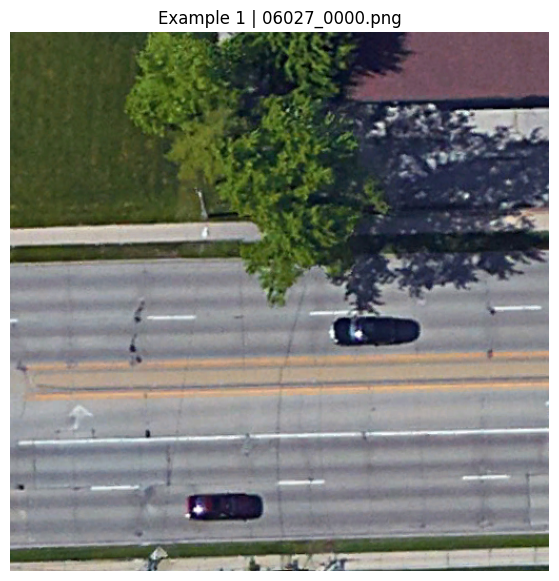

========== GROUND TRUTH ==========
The image from GoogleEarth shows a section of a straight road running east-west with two visible vehicles. The road has multiple lanes marked with white lines and arrows indicating direction of travel. On the lanes closest to the top of the image, there is a small dark-colored vehicle oriented horizontally. To the bottom, closer to the image edge, is another small vehicle, dark red in color.

========== PREDICTION ==========
The aerial image from GoogleEarth shows a section of an urban road with multiple vehicles and clear lane markings. There is one small vehicle located at the bottom-middle part of the image, while another small vehicle is positioned towards the top-right corner. The roads have distinct lanes and markings, and there are trees lining the sides of the road.




In [93]:
show_caption_predictions(
    val_subset[33:34],
    references[33:34],
    predictions[33:34],
    n=10
)

The high-resolution image from GoogleEarth features an urban scene with two small vehicles on a multi-lane road. The first vehicle is positioned at the bottom of the frame, while the second one is located towards the middle-right side of the image. Surrounding the road are various elements such as trees and a sidewalk.

In [94]:
def compute_bleu_scores(
    references,
    predictions,
):

    smoothie = SmoothingFunction().method3

    ref_tokens = [
        [ref.lower().split()]
        for ref in references
    ]

    pred_tokens = [
        pred.lower().split()
        for pred in predictions
    ]


    bleu1 = corpus_bleu(
        ref_tokens,
        pred_tokens,
        weights=(1, 0, 0, 0),
        smoothing_function=smoothie,
    )

    bleu2 = corpus_bleu(
        ref_tokens,
        pred_tokens,
        weights=(0.5, 0.5, 0, 0),
        smoothing_function=smoothie,
    )

    bleu3 = corpus_bleu(
        ref_tokens,
        pred_tokens,
        weights=(1/3, 1/3, 1/3, 0),
        smoothing_function=smoothie,
    )

    bleu4 = corpus_bleu(
        ref_tokens,
        pred_tokens,
        weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=smoothie,
    )


    return {
        "BLEU-1": bleu1 * 100,
        "BLEU-2": bleu2 * 100,
        "BLEU-3": bleu3 * 100,
        "BLEU-4": bleu4 * 100,
    }

In [95]:
def compute_meteor(
    references,
    predictions,
):

    scores = []

    for ref, pred in zip(
        references,
        predictions
    ):

        ref_tokens = ref.lower().split()
        pred_tokens = pred.lower().split()

        if len(pred_tokens) == 0:
            scores.append(0.0)
            continue

        score = meteor_score(
            [ref_tokens],
            pred_tokens,
        )

        scores.append(score)

    return np.mean(scores) * 100

In [96]:
def compute_rouge_l(
    references,
    predictions,
):

    scorer = rouge_scorer.RougeScorer(
        ["rougeL"],
        use_stemmer=True,
    )

    scores = []

    for ref, pred in zip(
        references,
        predictions
    ):

        result = scorer.score(
            ref,
            pred,
        )

        scores.append(
            result["rougeL"].fmeasure
        )

    return np.mean(scores) * 100

In [97]:
import torch
from bert_score import score


def compute_bertscore(references, predictions):
    """
    Compute BERTScore F1.

    references  : list of reference captions
    predictions : list of generated captions

    Returns:
        BERTScore F1 as percentage
    """

    device = "cuda" if torch.cuda.is_available() else "cpu"

    P, R, F1 = score(
        cands=predictions,
        refs=references,
        model_type="roberta-large",
        lang="en",
        device=device,
        batch_size=16,
        rescale_with_baseline=True
    )

    bertscore_f1 = F1.mean().item() * 100

    return bertscore_f1

In [98]:
bleu_scores = compute_bleu_scores(
    references,
    predictions,
)

meteor = compute_meteor(
    references,
    predictions,
)

rouge_l = compute_rouge_l(
    references,
    predictions,
)

bert_score_f1 = compute_bertscore(
    references,
    predictions,
)


E3_METRICS = {
    **bleu_scores,
    "BERT_SCORE_F1": bert_score_f1,
    "METEOR": meteor,
    "ROUGE-L": rouge_l,
}


print("\n========== E3 METRICS ==========")

for key, value in E3_METRICS.items():
    print(
        f"{key:10s}: {value:.4f}"
    )

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



========== E3 METRICS ==========
BLEU-1    : 40.5216
BLEU-2    : 24.1940
BLEU-3    : 14.9954
BLEU-4    : 9.7756
BERT_SCORE_F1: 45.9975
METEOR    : 31.9679
ROUGE-L   : 35.1619


In [99]:
avg_pred_len = np.mean([
    len(p.split())
    for p in predictions
])

avg_ref_len = np.mean([
    len(r.split())
    for r in references
])

print("Average predicted words:", avg_pred_len)
print("Average reference words:", avg_ref_len)

Average predicted words: 45.57
Average reference words: 47.96


In [100]:
OUTPUT_DIR = Path("/kaggle/working/VRSBench/E3_qwen25vl_3b")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# LoRA adapter
model.save_pretrained(
    OUTPUT_DIR / "lora_adapter"
)

# Processor
processor.save_pretrained(
    OUTPUT_DIR / "processor"
)


# Metrics
with open(
    OUTPUT_DIR / "metrics.json",
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        {
            "config": {
                "model": MODEL_ID,
                "train_samples": len(train_subset),
                "val_samples": len(val_subset),
                "epochs": EPOCHS,
                "batch_size": BATCH_SIZE,
                "learning_rate": {
                    "vision_params": 1e-5,
                    "llm_params": 5e-5,
                },
                "lora_r": LORA_R,
                "lora_alpha": LORA_ALPHA,
                "lora_dropout": LORA_DROPOUT,
                "min_pixels": MIN_PIXELS,
                "max_pixels": MAX_PIXELS,
            },

            "training": E3_HISTORY,

            "metrics": E3_METRICS,

            "caption_length": {
                "avg_prediction_words": avg_pred_len,
                "avg_reference_words": avg_ref_len,
            }
        },
        f,
        indent=2,
    )


# Predictions
with open(
    OUTPUT_DIR / "predictions.json",
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        [
            {
                "image_id": sample["image_id"],
                "reference": ref,
                "prediction": pred,
            }

            for sample, ref, pred in zip(
                val_records,
                references,
                predictions,
            )
        ],
        f,
        indent=2,
        ensure_ascii=False,
    )


print("E3 saved to:", OUTPUT_DIR)

E3 saved to: /kaggle/working/VRSBench/E3_qwen25vl_3b
